# SynPCG generation and experiment demonstration
**CS 598 Deep Learning for Healthcare · Tejaswi Sapkota · Group 3**

Presentation figures for our **Normal versus aortic stenosis (AS)** synthetic
heart-sound generator and Real / Syn / Syn→Real / Mixed experiment.

**Run with the `Python (PyHealth Project)` kernel, after the current pilot finishes.**
Open this notebook from `Github final` and choose **Run All**. Core figures need
only NumPy, SciPy, Matplotlib and the local generator. No model is trained, no
checkpoint is loaded, and no held-out predictions are made. Optional audio
players demonstrate synthetic sounds only; lower your volume before listening.

The examples are **synthetic illustrations, not clinical diagnostic evidence**.
They do not establish that our generator reproduces real disease physiology.
Only Normal and AS are implemented; AR and MR are outside this demonstration.

Figures export as 300 dpi PNG and SVG under `presentation_assets/` when enabled.
These are separate new files; original audio, split plans and training files
are never modified. Suggested slides: figures 01, 02, 04, 06 and 07.

In [1]:
from pathlib import Path
import csv
import hashlib
import json
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from scipy.signal import spectrogram, welch
from IPython.display import Audio, Markdown, display

# Change these paths if you move the notebook or use a teammate's machine.
CODE_DIR = Path.cwd()
DATA_WORKSPACE = Path.home() / "Documents/DL4H-runs/pilot-data"
RESULTS_DIR = Path.home() / "Documents/DL4H-runs/pilot-results"
SAVE_FIGURES = True
SHOW_AUDIO_PLAYERS = True
SHOW_COMPLETED_RESULTS = True
FIGURE_DIR = CODE_DIR / "presentation_assets"

if not (CODE_DIR / "synthetic_pcg.py").is_file():
    raise RuntimeError("Set CODE_DIR to Github final, or open Jupyter in that folder.")
sys.path.insert(0, str(CODE_DIR))
import synthetic_pcg as generator
if Path(generator.__file__).resolve() != (CODE_DIR / "synthetic_pcg.py").resolve():
    raise RuntimeError("A different generator is already imported. Restart the kernel.")

from synthetic_pcg import (
    AS_CONFIG, COMMON_CONFIG, SAMPLE_RATE, SYNTHESIS_PROFILE,
    generate_beat, generate_recording,
)

COLORS = {"Normal": "#247B83", "AS": "#C65D32", "S1": "#3658A4",
          "S2": "#4A9062", "background": "#8B8796", "ink": "#243447"}
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.family": "DejaVu Sans",
    "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.15, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "white",
})

def finish(fig, filename):
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        for extension in ("png", "svg"):
            fig.savefig(FIGURE_DIR / f"{filename}.{extension}", bbox_inches="tight")
    plt.show()
    plt.close(fig)

provenance = {
    "generator_sha256": hashlib.sha256((CODE_DIR / "synthetic_pcg.py").read_bytes()).hexdigest(),
    "reference_commit": SYNTHESIS_PROFILE["reference_commit"],
    "sample_rate": SAMPLE_RATE,
    "timing_policy": "reference",
    "note": "Deterministic illustration seeds; no clinical equivalence claim.",
}
print(json.dumps(provenance, indent=2))


{
  "generator_sha256": "b7edad730e9c36aba4bcfd9ee8f98cf7eb2423724ef282404feeb77ec941704f",
  "reference_commit": "1a5f600ce2a0a9e43514e20582da67081159a14a",
  "sample_rate": 8000,
  "timing_policy": "reference",
  "note": "Deterministic illustration seeds; no clinical equivalence claim."
}


## 1. How one beat is assembled

The generator builds S1 and S2 from oscillatory bursts, adds background
fluctuations/noise, and—for AS—adds a shaped noise component. This figure uses
one fixed set of base parameters. Its bottom panel compares the **same baseline**
with and without the murmur, isolating the generator's added contribution.

The shaded interval is the **implemented murmur window**, not a clinical
annotation. Our primary timing deliberately preserves the reference code's
unplaced-S1 rule, which can overlap the positioned S1. Do not present it as a
verified physiological systolic boundary. Raw component amplitudes below are
before full-recording scaling, filtering and cropping.

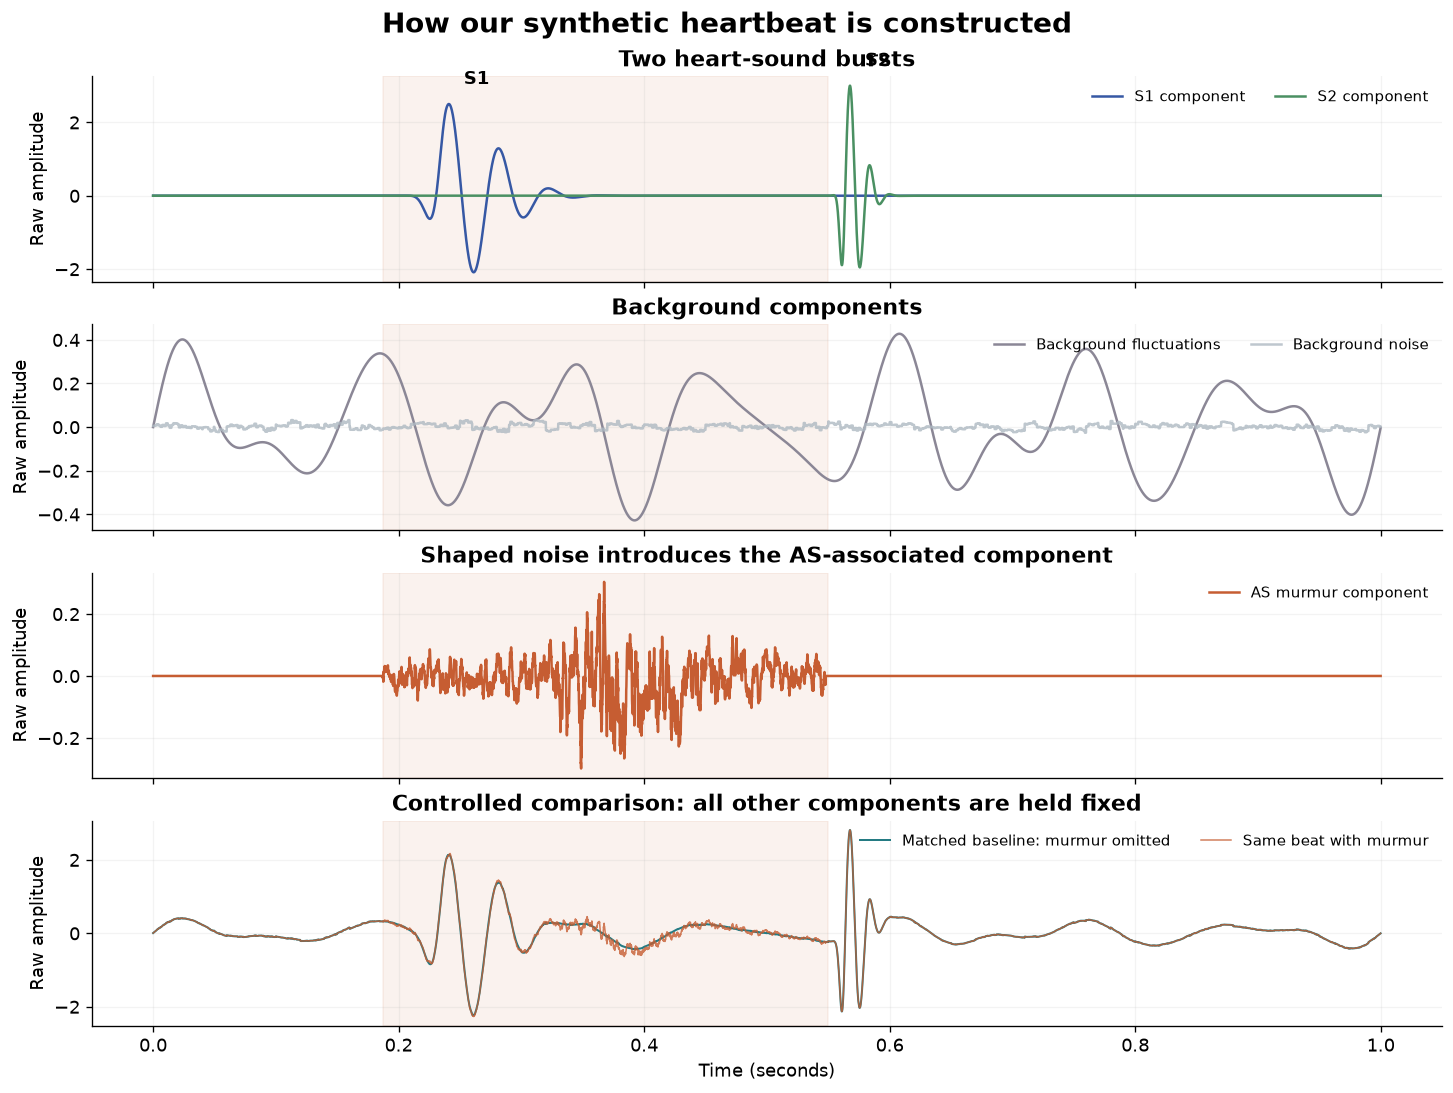

Implemented murmur window (seconds): (0.1871, 0.55)


In [2]:
parameters = {name: spec["base"] for name, spec in {**COMMON_CONFIG, **AS_CONFIG}.items()}
beat = generate_beat("AS", parameters, rng=np.random.default_rng(42), timing="reference")
t = beat["time"]
window = beat["murmur_window"]

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True, layout="constrained")
axes[0].plot(t, beat["s1"], color=COLORS["S1"], label="S1 component")
axes[0].plot(t, beat["s2"], color=COLORS["S2"], label="S2 component")
axes[0].set_title("Two heart-sound bursts")
for key in ("s1", "s2"):
    peak = int(np.argmax(np.abs(beat[key])))
    axes[0].annotate(key.upper(), (t[peak], beat[key][peak]),
                     xytext=(9, 12), textcoords="offset points", weight="bold")
axes[1].plot(t, beat["background"], color=COLORS["background"], label="Background fluctuations")
axes[1].plot(t, beat["noise"], color="#AEB9C2", alpha=0.8, label="Background noise")
axes[1].set_title("Background components")
axes[2].plot(t, beat["murmur"], color=COLORS["AS"], label="AS murmur component")
axes[2].set_title("Shaped noise introduces the AS-associated component")
axes[3].plot(t, beat["baseline"], color=COLORS["Normal"], lw=1.2,
             label="Matched baseline: murmur omitted")
axes[3].plot(t, beat["waveform"], color=COLORS["AS"], lw=0.9, alpha=0.8,
             label="Same beat with murmur")
axes[3].set_title("Controlled comparison: all other components are held fixed")
for ax in axes:
    ax.axvspan(*window, color=COLORS["AS"], alpha=0.08)
    ax.set_ylabel("Raw amplitude")
    ax.legend(loc="upper right", ncol=2, fontsize=9)
axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("How our synthetic heartbeat is constructed", fontsize=17, weight="bold")
finish(fig, "01_heartbeat_components")
print("Implemented murmur window (seconds):", tuple(round(x, 4) for x in window))


## 2. Complete Normal and AS recordings

Each example has **80,000 float32 samples: 10 seconds at 8 kHz**. These separately
generated recordings use a fixed seed for reproducibility. They are not
physiologically matched patient pairs. The same plot scale allows a direct view
of the exported waveform range without additional display normalization.

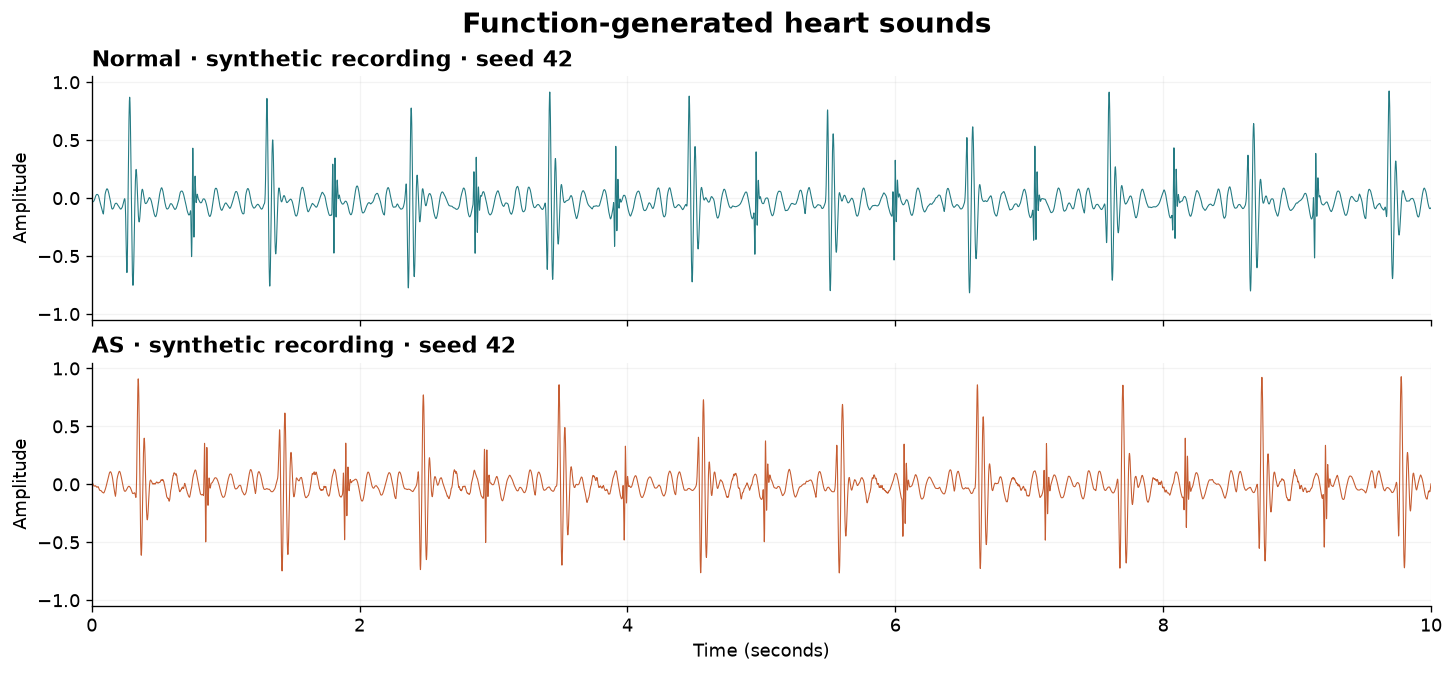

**Normal: synthetic audio, 10 seconds. Start with low volume.**

**AS: synthetic audio, 10 seconds. Start with low volume.**

In [3]:
examples = {}
for label in ("Normal", "AS"):
    waveform, metadata = generate_recording(label, seed=42)
    assert waveform.shape == (80000,) and np.isfinite(waveform).all()
    examples[label] = (waveform, metadata)

fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, sharey=True,
                         layout="constrained")
for ax, label in zip(axes, ("Normal", "AS")):
    waveform, meta = examples[label]
    ax.plot(np.arange(len(waveform)) / SAMPLE_RATE, waveform,
            color=COLORS[label], lw=0.65)
    ax.set_title(f"{label} · synthetic recording · seed 42", loc="left")
    ax.set_ylabel("Amplitude")
    ax.set_ylim(-1.05, 1.05)
    ax.set_xlim(0, 10)
axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("Function-generated heart sounds", fontsize=17, weight="bold")
finish(fig, "02_normal_as_full_recordings")

if SHOW_AUDIO_PLAYERS:
    for label, (waveform, _) in examples.items():
        display(Markdown(f"**{label}: synthetic audio, 10 seconds. Start with low volume.**"))
        display(Audio(waveform, rate=SAMPLE_RATE, normalize=False))


## 3. Zoom in and show variation

The three-second view makes recurring heart-sound bursts easier to see.
Different seeds demonstrate that the generator produces multiple examples,
rather than duplicating one waveform. This is a visual sanity check, not a
statistical test of realism or class separability.

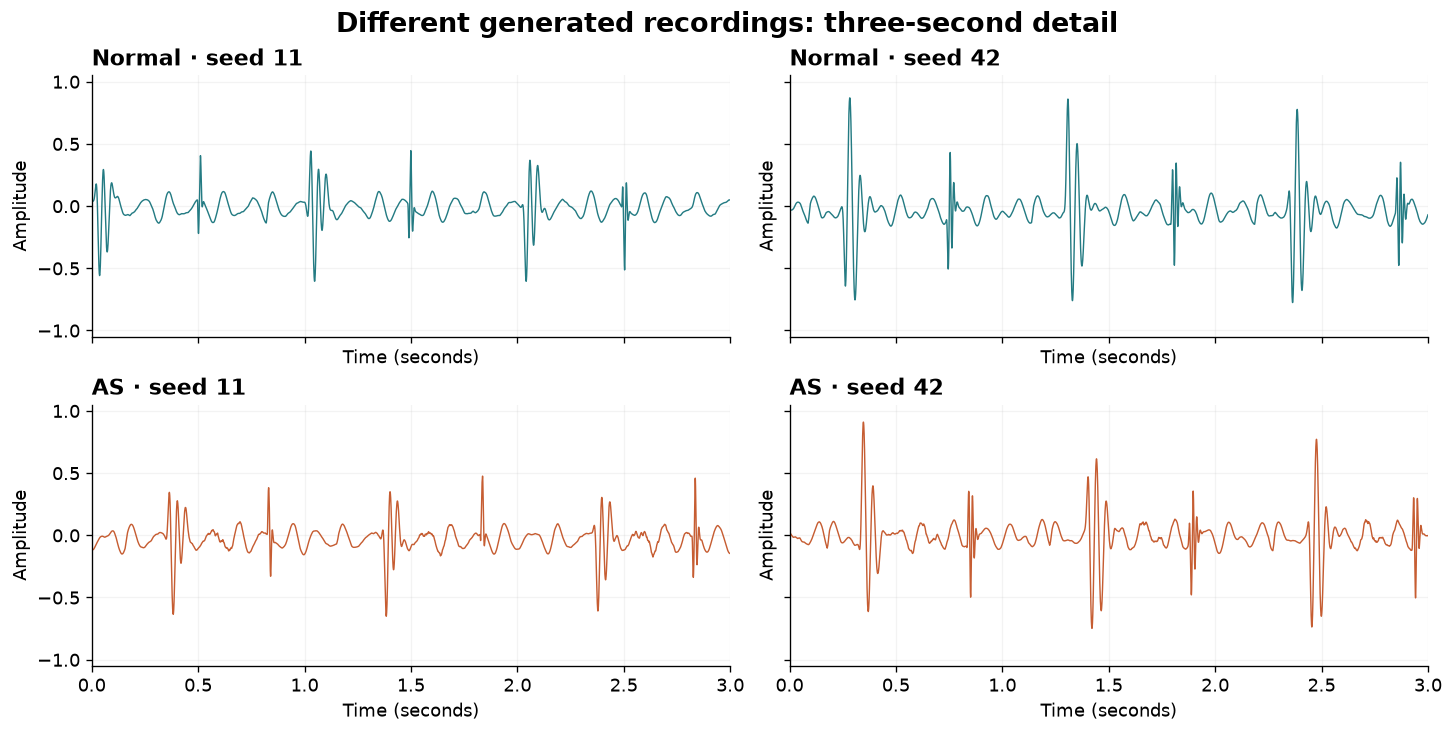

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True,
                         layout="constrained")
for row, label in enumerate(("Normal", "AS")):
    for col, seed in enumerate((11, 42)):
        waveform = (examples[label][0] if seed == 42 else generate_recording(label, seed=seed)[0])
        n = 3 * SAMPLE_RATE
        axes[row, col].plot(np.arange(n) / SAMPLE_RATE, waveform[:n],
                            color=COLORS[label], lw=0.85)
        axes[row, col].set_title(f"{label} · seed {seed}", loc="left")
        axes[row, col].set_ylim(-1.05, 1.05)
        axes[row, col].set_xlim(0, 3)
        axes[row, col].set_xlabel("Time (seconds)")
        axes[row, col].set_ylabel("Amplitude")
fig.suptitle("Different generated recordings: three-second detail", fontsize=16, weight="bold")
finish(fig, "03_recording_variation_zoom")


## 4. Spectrograms show when different frequencies occur

Waveforms show amplitude over time. Spectrograms add the frequency dimension.
Both examples use the **same frequency range and color scale**, with no
independent image rescaling. We show 0–500 Hz for readability; this is a display
choice, not an additional training filter. The plots describe two synthetic
examples and are not evidence of diagnostic performance.

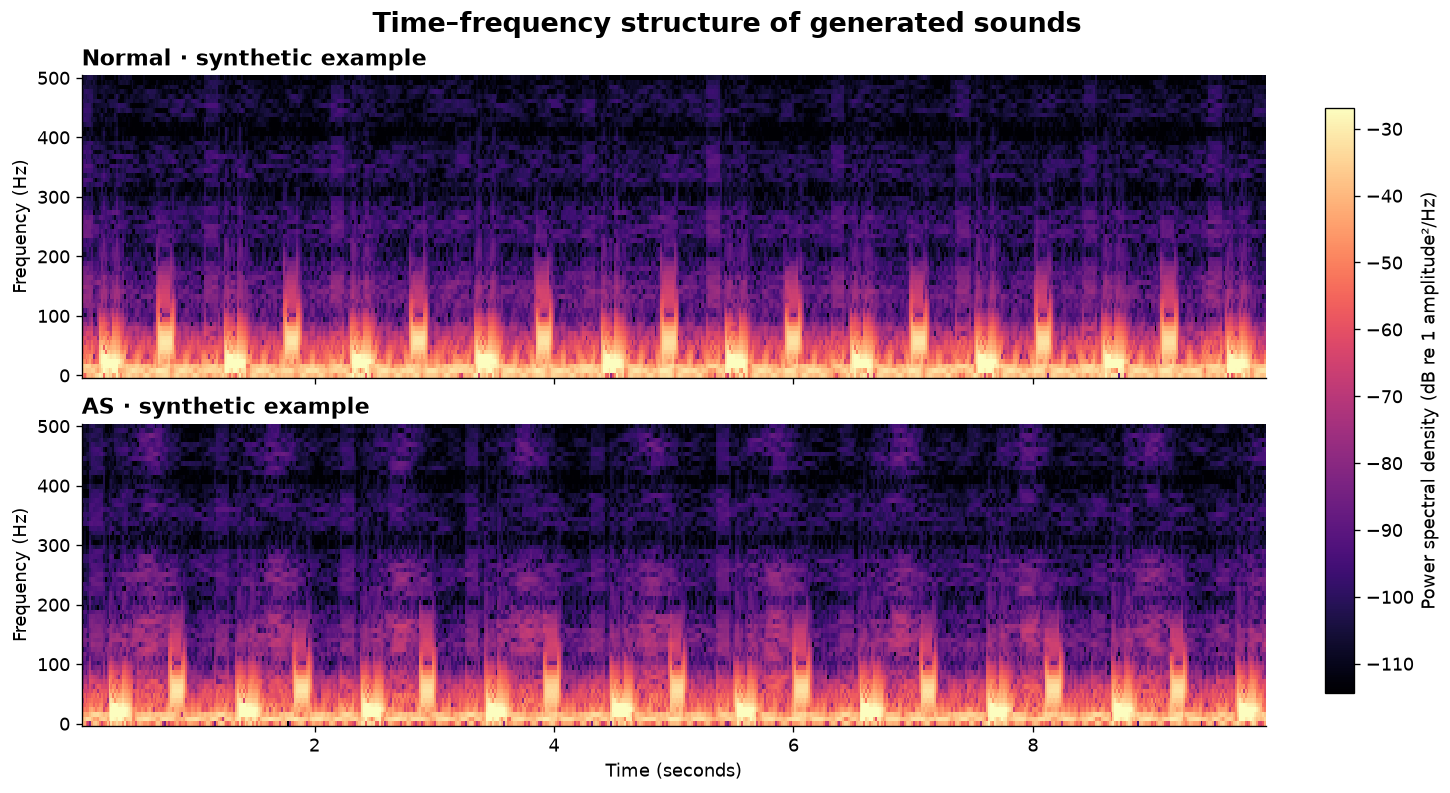

In [5]:
spectra = {}
for label, (waveform, _) in examples.items():
    freq, times, power = spectrogram(waveform, fs=SAMPLE_RATE, nperseg=1024,
                                    noverlap=896, detrend=False, scaling="density")
    keep = freq <= 500
    spectra[label] = (times, freq[keep], 10 * np.log10(power[keep] + 1e-12))
values = np.concatenate([entry[2].ravel() for entry in spectra.values()])
vmin, vmax = np.quantile(values, [0.05, 0.995])
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, sharey=True,
                         layout="constrained")
for ax, label in zip(axes, ("Normal", "AS")):
    times, freq, db = spectra[label]
    image = ax.pcolormesh(times, freq, db, shading="auto", cmap="magma",
                          vmin=vmin, vmax=vmax, rasterized=True)
    ax.set_title(f"{label} · synthetic example", loc="left")
    ax.set_ylabel("Frequency (Hz)")
    ax.grid(False)
axes[-1].set_xlabel("Time (seconds)")
fig.colorbar(image, ax=axes, label="Power spectral density (dB re 1 amplitude²/Hz)", shrink=0.9)
fig.suptitle("Time–frequency structure of generated sounds", fontsize=16, weight="bold")
finish(fig, "04_normal_as_spectrograms")


## 5. Frequency-content comparison

Welch spectra summarize frequency content across an entire recording. Each
recording's spectrum is normalized by its own total power to compare **shape**,
not loudness. Shading is the middle 50% across eight deliberately small,
seeded examples per class. It is **not a confidence interval** and does not
establish a population difference. No real clinical data are used here.

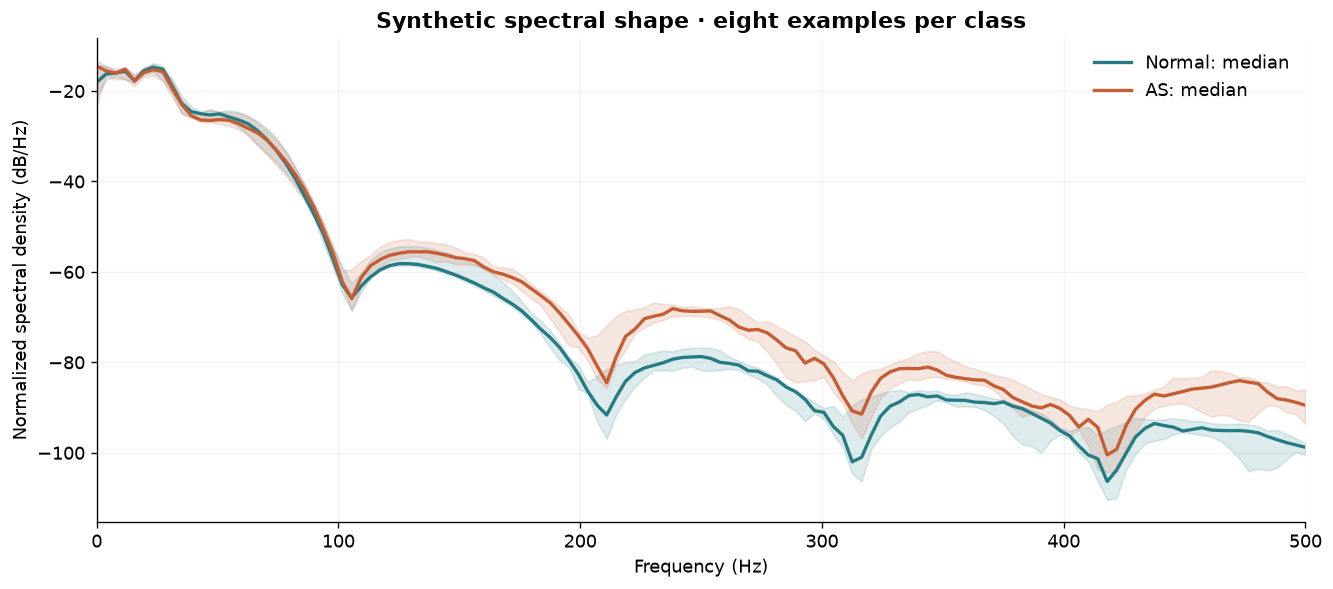

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.8), layout="constrained")
for label in ("Normal", "AS"):
    distributions = []
    for seed in range(8):
        waveform, _ = generate_recording(label, seed=seed)
        freq, psd = welch(waveform, fs=SAMPLE_RATE, nperseg=2048, detrend=False)
        psd = psd / max(float(np.sum(psd) * (freq[1] - freq[0])), 1e-15)
        distributions.append(10 * np.log10(psd + 1e-15))
    q25, median, q75 = np.quantile(distributions, [0.25, 0.5, 0.75], axis=0)
    keep = freq <= 500
    ax.plot(freq[keep], median[keep], color=COLORS[label], lw=2, label=f"{label}: median")
    ax.fill_between(freq[keep], q25[keep], q75[keep], color=COLORS[label], alpha=0.15)
ax.set(xlabel="Frequency (Hz)", ylabel="Normalized spectral density (dB/Hz)",
       xlim=(0, 500), title="Synthetic spectral shape · eight examples per class")
ax.legend()
finish(fig, "05_spectral_shape_examples")


## 6. The study design and our extension

All protocols ultimately target the **same held-out real patients** in full-mode
evaluation. Syn is selected using synthetic validation; the other protocols
use real validation. Mixed starts from random weights and is our extension.
Syn→Real reuses the selected Syn checkpoint with a fresh optimizer.

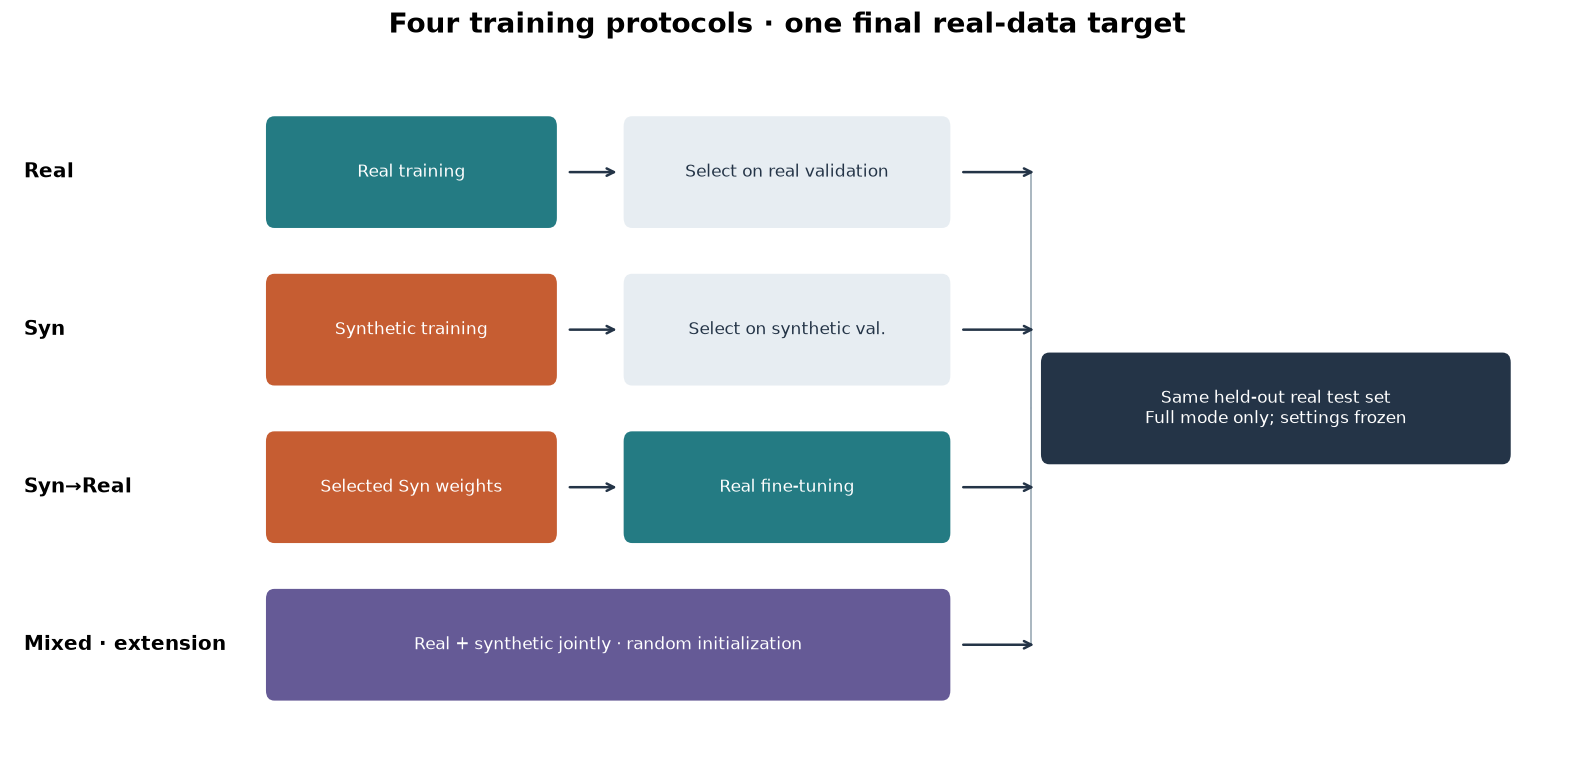

In [7]:
fig, ax = plt.subplots(figsize=(13, 6.2), layout="constrained")
ax.set(xlim=(0, 13), ylim=(-0.5, 4.3))
ax.axis("off")

def box(x, y, width, text, color):
    patch = FancyBboxPatch((x, y - 0.32), width, 0.64,
                           boxstyle="round,pad=0.07", fc=color, ec="none")
    ax.add_patch(patch)
    ax.text(x + width / 2, y, text, ha="center", va="center", fontsize=10,
            color="white" if color != "#E7EDF2" else COLORS["ink"])

def arrow(x1, x2, y):
    ax.annotate("", (x2, y), (x1, y),
                 arrowprops={"arrowstyle": "->", "color": COLORS["ink"], "lw": 1.5})

rows = [(3.5, "Real"), (2.4, "Syn"), (1.3, "Syn→Real"), (0.2, "Mixed · extension")]
for y, label in rows:
    ax.text(0.1, y, label, fontsize=12, weight="bold", va="center")
box(2.2, 3.5, 2.3, "Real training", COLORS["Normal"])
box(2.2, 2.4, 2.3, "Synthetic training", COLORS["AS"])
box(2.2, 1.3, 2.3, "Selected Syn weights", COLORS["AS"])
arrow(4.65, 5.1, 1.3)
box(5.2, 1.3, 2.6, "Real fine-tuning", COLORS["Normal"])
box(2.2, 0.2, 5.6, "Real + synthetic jointly · random initialization", "#655A96")
box(5.2, 3.5, 2.6, "Select on real validation", "#E7EDF2")
arrow(4.65, 5.1, 3.5)
box(5.2, 2.4, 2.6, "Select on synthetic val.", "#E7EDF2")
arrow(4.65, 5.1, 2.4)
for y, _ in rows:
    arrow(7.95, 8.6, y)
box(8.7, 1.85, 3.8, "Same held-out real test set\nFull mode only; settings frozen", "#243447")
for y in (3.5, 2.4, 1.3, 0.2):
    ax.plot([8.55, 8.55], [y, 1.85], color="#9BAAB5", lw=1)
ax.set_title("Four training protocols · one final real-data target", fontsize=17, pad=15)
finish(fig, "06_protocol_design")


## 7. Patient-level separation

Multiple recordings belong to the same patient. Splitting recordings at random
could place one person's sounds in both training and testing. Our saved splits
keep patients separate and hold the same test patients fixed across runs.
This chart uses **split metadata only**, never predictions or test performance.
It shows our selected cohort, whose counts differ from the paper's experiments.

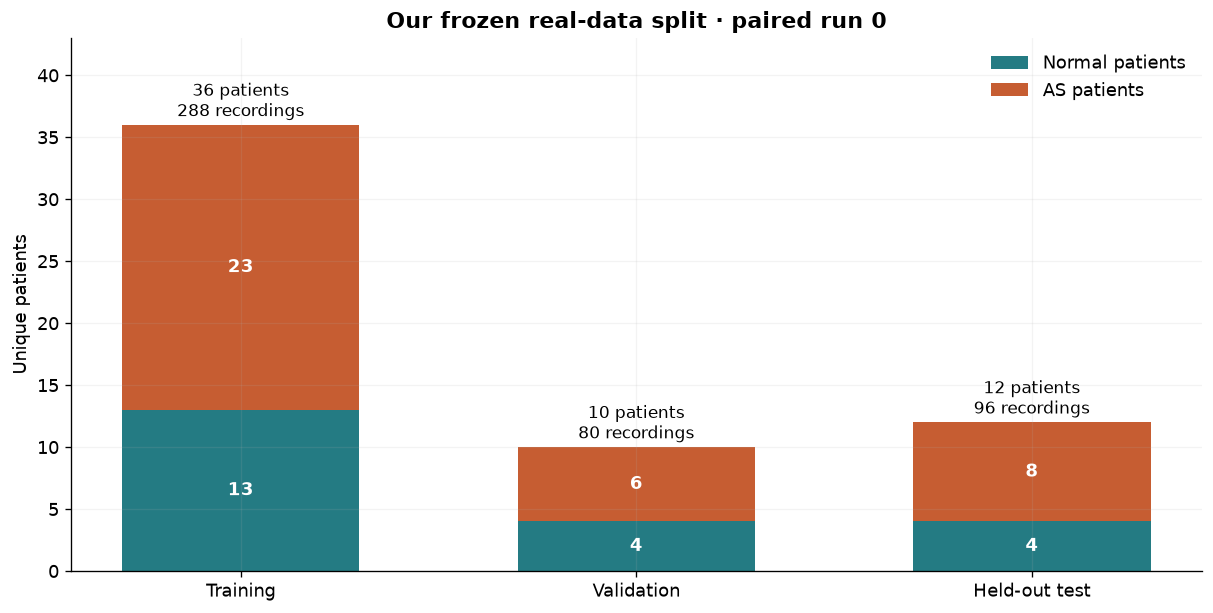

In [8]:
setup_path = DATA_WORKSPACE / "data_setup.json"
if not setup_path.is_file():
    print("Optional cohort chart skipped: set DATA_WORKSPACE to a prepared workspace.")
else:
    setup = json.loads(setup_path.read_text())
    plan = json.loads((DATA_WORKSPACE / setup["real_plan"]).read_text())
    run = plan["runs"][0]
    partitions = ("train", "validation", "test")
    names = ("Training", "Validation", "Held-out test")
    normal = [sum(plan["patients"][pid]["label"] == 0 for pid in run[p]) for p in partitions]
    positive = [sum(plan["patients"][pid]["label"] == 1 for pid in run[p]) for p in partitions]
    recording_counts = [sum(len(plan["patients"][pid]["recordings"]) for pid in run[p])
                        for p in partitions]
    fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
    x = np.arange(3)
    ax.bar(x, normal, color=COLORS["Normal"], label="Normal patients", width=0.6)
    ax.bar(x, positive, bottom=normal, color=COLORS["AS"], label="AS patients", width=0.6)
    for i, (n, a, recordings) in enumerate(zip(normal, positive, recording_counts)):
        ax.text(i, n / 2, str(n), ha="center", va="center", color="white", weight="bold")
        ax.text(i, n + a / 2, str(a), ha="center", va="center", color="white", weight="bold")
        ax.text(i, n + a + 0.7, f"{n+a} patients\n{recordings} recordings", ha="center", fontsize=10)
    ax.set_xticks(x, names)
    ax.set(ylim=(0, max(np.array(normal) + positive) + 7), ylabel="Unique patients",
           title="Our frozen real-data split · paired run 0")
    ax.legend(loc="upper right")
    finish(fig, "07_patient_split")


## 8. Optional completed-run learning curves and workload

These cells read only JSON histories. They never load model checkpoints, train,
or predict. They **skip results unless the entire selected suite is complete**.
The notebook does not snapshot a running stage as a finished experiment.

Pilot/smoke curves are preliminary validation evidence, not paper reproduction.
Syn's validation domain is synthetic; the others use real validation, so do not
rank their validation AUROC values against each other. Losses also use different
class weighting/domain mixtures. Best checkpoints are selected by validation
loss, not by the largest AUROC shown on a plot.

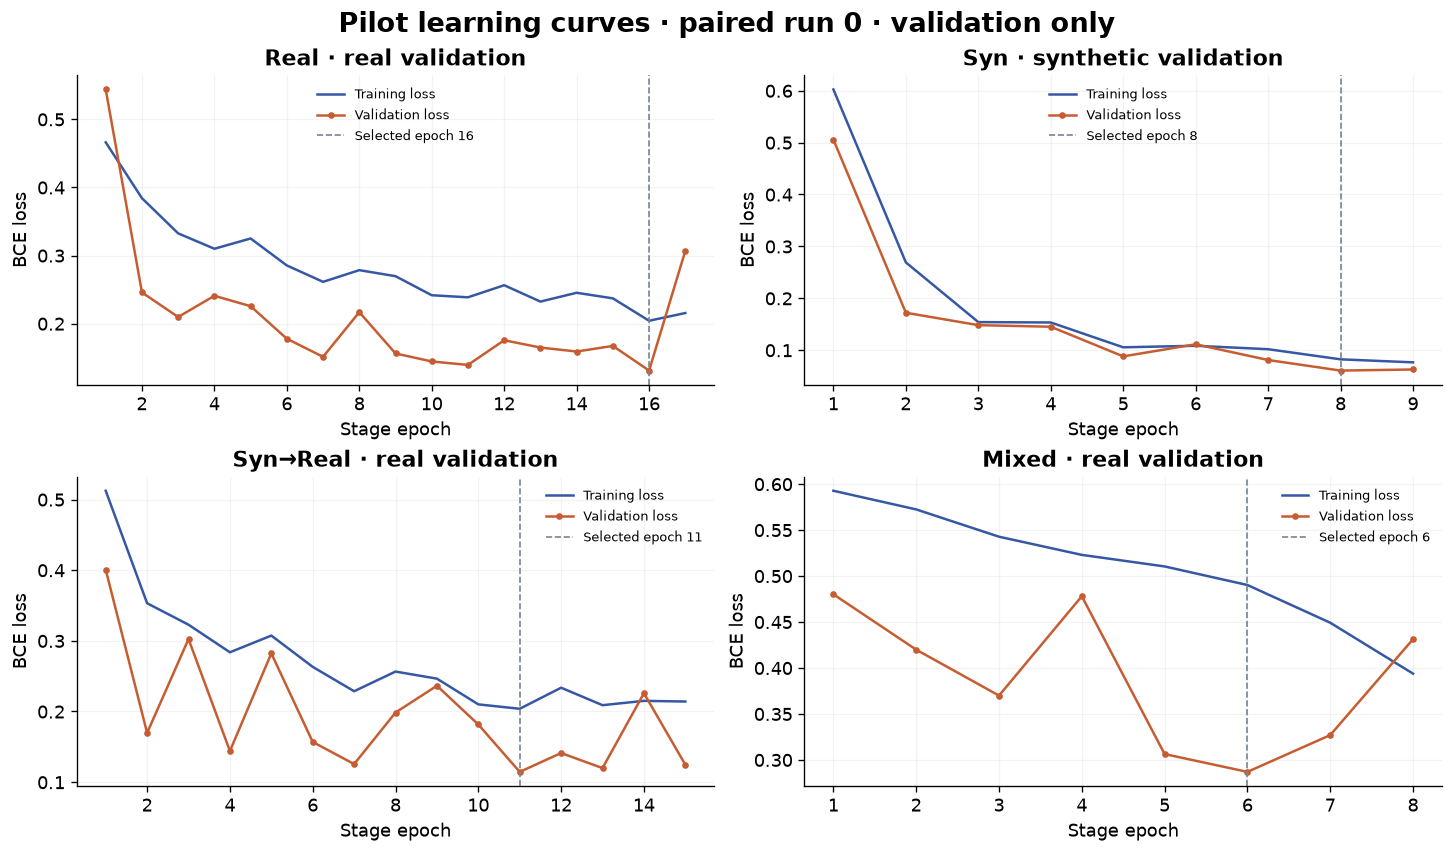

In [9]:
completed_results = None
status_path = RESULTS_DIR / "suite_status.json"
if not SHOW_COMPLETED_RESULTS:
    print("Saved-result panels disabled.")
elif not status_path.is_file():
    print("Result panels skipped: suite completion has not been recorded yet.")
else:
    status = json.loads(status_path.read_text())
    if status.get("status") != "complete":
        print("Result panels skipped: suite status is", status.get("status"))
    else:
        configuration = json.loads((RESULTS_DIR / "suite_config.json").read_text())
        mode = configuration["settings"]["mode"]
        run_index = configuration["settings"]["run_indices"][0]
        histories = {}
        for protocol in ("real", "syn", "syn2real", "mixed"):
            path = RESULTS_DIR / f"run_{run_index:02d}" / protocol / "history.json"
            histories[protocol] = json.loads(path.read_text())
        completed_results = (mode, run_index, histories)
        labels = {"real": "Real", "syn": "Syn", "syn2real": "Syn→Real", "mixed": "Mixed"}
        fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
        for ax, (protocol, history) in zip(axes.flat, histories.items()):
            epochs = [h["epoch"] for h in history]
            evaluated = [h for h in history if "validation" in h]
            ax.plot(epochs, [h["train_loss"] for h in history], color="#3658A4", label="Training loss")
            ax.plot([h["epoch"] for h in evaluated], [h["validation"]["loss"] for h in evaluated],
                    color=COLORS["AS"], marker=".", label="Validation loss")
            best = min(evaluated, key=lambda h: h["validation"]["loss"])
            ax.axvline(best["epoch"], color="#788491", ls="--", lw=1,
                       label=f"Selected epoch {best['epoch']}")
            domain = "synthetic" if protocol == "syn" else "real"
            ax.set(title=f"{labels[protocol]} · {domain} validation", xlabel="Stage epoch", ylabel="BCE loss")
            ax.legend(fontsize=8)
        fig.suptitle(f"{mode.capitalize()} learning curves · paired run {run_index} · validation only",
                     fontsize=16, weight="bold")
        finish(fig, "08_completed_run_learning_curves")


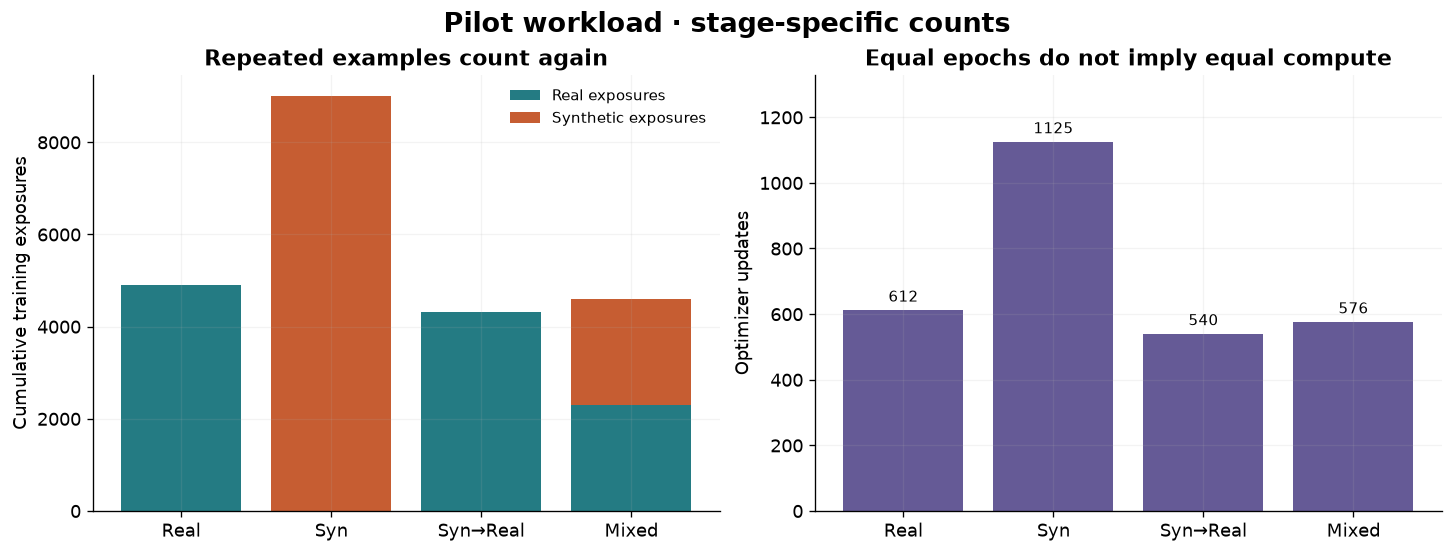

Syn→Real bars show fine-tuning only. Shared synthetic pretraining is the Syn stage;
it is reused, not executed or charged a second time. Mixed starts from random weights.


In [10]:
if completed_results is not None:
    mode, run_index, histories = completed_results
    protocols = list(histories)
    names = ["Real", "Syn", "Syn→Real", "Mixed"]
    real_exposures = [histories[p][-1]["real_seen"] for p in protocols]
    syn_exposures = [histories[p][-1]["synthetic_seen"] for p in protocols]
    updates = [histories[p][-1]["steps"] for p in protocols]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    x = np.arange(4)
    axes[0].bar(x, real_exposures, color=COLORS["Normal"], label="Real exposures")
    axes[0].bar(x, syn_exposures, bottom=real_exposures, color=COLORS["AS"], label="Synthetic exposures")
    axes[0].set_xticks(x, names)
    axes[0].set(ylabel="Cumulative training exposures", title="Repeated examples count again")
    axes[0].legend(fontsize=9)
    bars = axes[1].bar(x, updates, color="#655A96")
    axes[1].set_xticks(x, names)
    axes[1].bar_label(bars, padding=3, fontsize=9)
    axes[1].set(ylabel="Optimizer updates", title="Equal epochs do not imply equal compute")
    axes[1].set_ylim(0, max(updates) * 1.18)
    fig.suptitle(f"{mode.capitalize()} workload · stage-specific counts", fontsize=16, weight="bold")
    finish(fig, "09_completed_run_workload")
    print("Syn→Real bars show fine-tuning only. Shared synthetic pretraining is the Syn stage;")
    print("it is reused, not executed or charged a second time. Mixed starts from random weights.")


## Suggested presentation sequence

1. **Motivation:** real labeled heart sounds are scarce; can synthetic pretraining help?
2. **Method:** figure 01 explains how sound components are assembled.
3. **Demonstration:** figure 02 or 03, optionally play a few seconds of synthetic audio.
4. **Signal inspection:** figure 04 adds the frequency/time view.
5. **Reproducibility:** figure 07 explains patient separation and the locked test set.
6. **Study design:** figure 06 distinguishes reproduction protocols from the Mixed extension.
7. **Results:** show completed pilot curves only as preliminary software/learning evidence;
   replace with five-run held-out results for the final scientific comparison.

### Scope and source attribution

- Generator/experiment workflow: Tejaswi Sapkota, developed with AI assistance.
- Real-data task: Michael Moser. ResNet1D integration/model: Franko Hysaj.
- Nonaka et al., *Boosting Phonocardiogram Classification Performance with Function
  Generated Data*, ML4H 2025 / PMLR 297:
  https://proceedings.mlr.press/v297/nonaka26a.html
- Reference implementation: https://github.com/seitalab/SynPCG at revision
  `1a5f600ce2a0a9e43514e20582da67081159a14a`.
- See `EXPERIMENT_POLICY.md`, `GENERATOR_README.md` and `REFERENCE_AUDIT.txt` for
  sampling, cohort, normalization, cropping, augmentation and generator differences.

This notebook makes no license-clearance or clinical-fidelity claim. It does not
alter the training policy or evaluate the real test set.